## Thiết lập chung

### Thư viện

In [4]:
# 14–19. Thư viện dùng chung; cài sẵn torch, transformers, datasets,
# scikit-learn, pandas, numpy, matplotlib, psutil và IPython.
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import gc
import random
import tempfile
import threading
import time
from contextlib import nullcontext
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import torch
from torch import nn
from torch.utils.data import DataLoader
from transformers import AutoConfig, AutoModel, AutoTokenizer
from datasets import ClassLabel, load_dataset
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
)
from IPython.display import display

### Cấu hình

In [5]:
# Cấu hình chung: mọi chế độ dùng cùng epoch, LR, batch và tokenizer.
CHECKPOINT = "google-bert/bert-base-uncased"
SEED = 42
BATCH_SIZE = 16
EPOCHS = 3
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
MAX_LENGTH = 128
VALIDATION_SIZE = 0.2
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
LABELS = ("negative", "positive")
PADDING = "max_length"
DATA_FRACTIONS = (0.10, 0.25, 0.50, 1.00)
SEQUENCE_LENGTHS = (64, 128, 256)
DOMAIN_B_DATASET = "fancyzhx/amazon_polarity"

# Tìm thư mục đích từ NLP hoặc lab08, không phụ thuộc đường dẫn máy.
cwd = Path.cwd().resolve()
LAB_DIR = cwd if (cwd / "pretrained_classification.py").is_file() else cwd / "lab08"
if not (LAB_DIR / "pretrained_classification.py").is_file():
    raise FileNotFoundError("Mở kernel từ thư mục NLP hoặc lab08.")
# Checkpoint tạm chỉ được tạo khi người dùng chạy notebook.
RUN_DIR = Path(tempfile.mkdtemp(prefix="lab08_runs_"))


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)


set_seed(SEED)
print("Thiết bị:", DEVICE)
print("Ảnh sẽ lưu tại:", LAB_DIR)
print("Epoch:", EPOCHS, "| batch:", BATCH_SIZE, "| LR:", LEARNING_RATE)

Thiết bị: cuda
Ảnh sẽ lưu tại: C:\Users\tasdus_117\Desktop\NLP\lab08
Epoch: 3 | batch: 16 | LR: 2e-05


### Dữ liệu IMDb và token hóa

In [6]:
# IMDb: tách validation phân tầng từ train; test chính thức giữ nguyên.
tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT)
# IMDb có thể đặt tên nhãn là neg/pos thay vì negative/positive.
def normalize_binary_labels(data):
    aliases = {"neg": 0, "negative": 0, "pos": 1, "positive": 1}
    feature = data.features["label"]
    if not isinstance(feature, ClassLabel):
        raise TypeError("Cần nhãn ClassLabel để kiểm tra ý nghĩa nhãn gốc.")
    names = [name.strip().lower() for name in feature.names]
    if len(names) != 2 or any(name not in aliases for name in names):
        raise ValueError(f"Không nhận diện được hai nhãn cảm xúc: {feature.names}")
    mapping = {index: aliases[name] for index, name in enumerate(names)}
    if set(mapping.values()) != {0, 1}:
        raise ValueError(f"Ánh xạ nhãn không hợp lệ: {mapping}")
    # Đổi cả ID và metadata; giữ nguyên thứ tự mẫu và split.
    if mapping != {0: 0, 1: 1}:
        data = data.map(lambda batch: {"label": [mapping[int(label)] for label in batch["label"]]},
                        batched=True)
    return data.cast_column("label", ClassLabel(names=list(LABELS)))


imdb = load_dataset("stanfordnlp/imdb")
for split_name in ("train", "test"):
    imdb[split_name] = normalize_binary_labels(imdb[split_name])
partition = imdb["train"].train_test_split(
    test_size=VALIDATION_SIZE, seed=SEED, stratify_by_column="label"
)
train_data = partition["train"]
validation_data = partition["test"]
test_data = imdb["test"]


def tokenize_data(data, max_length):
    def encode(batch):
        return tokenizer(
            batch["text"], padding=PADDING, truncation=True,
            max_length=max_length, return_token_type_ids=False,
        )
    encoded = data.map(encode, batched=True, remove_columns=data.column_names)
    encoded = encoded.add_column("labels", list(data["label"]))
    encoded.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
    return encoded


# Chỉ cache dữ liệu token hóa có cùng split, tokenizer và độ dài.
token_cache = {}

def get_tokens(data, max_length):
    key = (data._fingerprint, CHECKPOINT, PADDING, max_length)
    if key not in token_cache:
        token_cache[key] = tokenize_data(data, max_length)
    return token_cache[key]


def make_loader(encoded, shuffle=False):
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(
        encoded, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0,
        generator=generator, pin_memory=DEVICE.type == "cuda",
    )


def metric_scores(y_true, y_pred):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=[0, 1], average="macro", zero_division=0
    )
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision, "Recall": recall, "F1": f1}


display(pd.DataFrame([
    {"Split": name, "# Examples": len(data),
     "Tỷ lệ positive": np.mean(data["label"])}
    for name, data in [("train", train_data), ("validation", validation_data),
                       ("test", test_data)]
]))

Casting the dataset:   0%|          | 0/25000 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/25000 [00:00<?, ? examples/s]

,Split,# Examples,Tỷ lệ positive
0,train,20000,0.5
1,validation,5000,0.5
2,test,25000,0.5


### Mô hình và đánh giá

In [7]:
# Kiến trúc gốc: BERT [CLS] -> Linear(hidden_size, 2), không softmax trước loss.
class SentimentClassifier(nn.Module):
    def __init__(self, mode):
        super().__init__()
        if mode not in {"scratch", "pretrained", "frozen"}:
            raise ValueError(mode)
        if mode == "scratch":
            config = AutoConfig.from_pretrained(CHECKPOINT)
            self.encoder = AutoModel.from_config(config)
        else:
            self.encoder = AutoModel.from_pretrained(CHECKPOINT)
        self.classifier = nn.Linear(self.encoder.config.hidden_size, 2)
        self.frozen = mode == "frozen"
        if self.frozen:
            self.encoder.requires_grad_(False)
            self.encoder.eval()

    def train(self, mode=True):
        super().train(mode)
        if self.frozen:
            self.encoder.eval()
        return self

    def forward(self, input_ids, attention_mask):
        context = torch.no_grad() if self.frozen else nullcontext()
        with context:
            output = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        return self.classifier(output.last_hidden_state[:, 0, :])


def create_model(mode):
    set_seed(SEED)
    return SentimentClassifier(mode).to(DEVICE)


@torch.inference_mode()
def evaluate(model, loader, collect_probabilities=False):
    model.eval()
    true_labels, predictions, probabilities = [], [], []
    for batch in loader:
        logits = model(
            input_ids=batch["input_ids"].to(DEVICE),
            attention_mask=batch["attention_mask"].to(DEVICE),
        )
        true_labels.extend(batch["labels"].tolist())
        predictions.extend(logits.argmax(dim=-1).cpu().tolist())
        if collect_probabilities:
            probabilities.append(logits.softmax(dim=-1).cpu().numpy())
    scores = metric_scores(true_labels, predictions)
    if collect_probabilities:
        return scores, np.asarray(true_labels), np.asarray(predictions), np.concatenate(probabilities)
    return scores


def collect_predictions(model, data, max_length):
    scores, truth, predicted, probabilities = evaluate(
        model, make_loader(get_tokens(data, max_length)), collect_probabilities=True
    )
    rows = pd.DataFrame({
        "sample_id": np.arange(len(data)), "text": list(data["text"]),
        "true_label": truth, "predicted_label": predicted,
        "p_negative": probabilities[:, 0], "p_positive": probabilities[:, 1],
        "confidence": probabilities.max(axis=1), "correct": truth == predicted,
    })
    return scores, rows

### Huấn luyện và đo tài nguyên

In [8]:
# Bộ nhớ riêng từng lần: CUDA max_memory_allocated; CPU lấy mẫu RSS mỗi 10 ms.
# Peak gồm model đang nạp, training và validation; không gồm token hóa/test.
class PeakMemory:
    def __enter__(self):
        self.process = psutil.Process(os.getpid())
        self.stop = threading.Event()
        if DEVICE.type == "cuda":
            torch.cuda.synchronize(DEVICE)
            torch.cuda.reset_peak_memory_stats(DEVICE)
        else:
            self.baseline = self.process.memory_info().rss
            self.peak = self.baseline
            self.thread = threading.Thread(target=self.sample, daemon=True)
            self.thread.start()
        return self

    def sample(self):
        while not self.stop.wait(0.01):
            self.peak = max(self.peak, self.process.memory_info().rss)

    def __exit__(self, exc_type, exc, tb):
        if DEVICE.type == "cuda":
            torch.cuda.synchronize(DEVICE)
            self.peak_mib = torch.cuda.max_memory_allocated(DEVICE) / 2**20
            self.extra_mib = None
        else:
            self.peak = max(self.peak, self.process.memory_info().rss)
            self.stop.set()
            self.thread.join()
            self.peak_mib = self.peak / 2**20
            self.extra_mib = (self.peak - self.baseline) / 2**20


def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)


def release_memory():
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


def training_signature(mode, data, max_length):
    return (
        CHECKPOINT, type(tokenizer).__name__, len(tokenizer), mode, SEED,
        data._fingerprint, validation_data._fingerprint, test_data._fingerprint,
        BATCH_SIZE, EPOCHS, LEARNING_RATE, WEIGHT_DECAY, max_length, PADDING,
        str(DEVICE), "AdamW", "CLS-Linear-2", "best-validation-macro-F1",
    )


def train_model(model, train_loader, validation_loader, checkpoint_path):
    trainable = [parameter for parameter in model.parameters() if parameter.requires_grad]
    optimizer = torch.optim.AdamW(trainable, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    optimizer_ids = {id(p) for group in optimizer.param_groups for p in group["params"]}
    assert optimizer_ids == {id(p) for p in model.parameters() if p.requires_grad}
    if model.frozen:
        assert all(not p.requires_grad for p in model.encoder.parameters())
        assert optimizer_ids == {id(p) for p in model.classifier.parameters()}
    loss_function = nn.CrossEntropyLoss()
    history, best_f1 = [], -float("inf")
    for epoch in range(1, EPOCHS + 1):
        model.train()
        assert not model.frozen or not model.encoder.training
        loss_sum, count = 0.0, 0
        for batch in train_loader:
            optimizer.zero_grad(set_to_none=True)
            labels = batch["labels"].to(DEVICE)
            logits = model(input_ids=batch["input_ids"].to(DEVICE),
                           attention_mask=batch["attention_mask"].to(DEVICE))
            loss = loss_function(logits, labels)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * labels.size(0)
            count += labels.size(0)
        validation = evaluate(model, validation_loader)
        history.append({"epoch": epoch, "loss": loss_sum / count, **validation})
        print(f"Epoch {epoch}/{EPOCHS}: loss={loss_sum/count:.4f}, "
              f"validation Accuracy={validation['Accuracy']:.4f}, F1={validation['F1']:.4f}")
        if validation["F1"] > best_f1:
            best_f1 = validation["F1"]
            torch.save(model.state_dict(), checkpoint_path)
    return history


def run_experiment(mode, data, max_length=MAX_LENGTH, reuse=None):
    signature = training_signature(mode, data, max_length)
    if reuse is not None and reuse["signature"] == signature:
        print("Dùng lại kết quả có cấu hình và split trùng khớp.")
        return reuse
    train_loader = make_loader(get_tokens(data, max_length), shuffle=True)
    validation_loader = make_loader(get_tokens(validation_data, max_length))
    test_loader = make_loader(get_tokens(test_data, max_length))
    release_memory()
    model = create_model(mode)
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    handle, path = tempfile.mkstemp(prefix=f"{mode}_{max_length}_", suffix=".pt", dir=RUN_DIR)
    os.close(handle)
    # Thời gian cùng phạm vi: train, validation và lưu checkpoint tốt nhất.
    # Không tính tải model/dữ liệu, token hóa, nạp lại checkpoint hoặc test.
    with PeakMemory() as memory:
        synchronize()
        start = time.perf_counter()
        history = train_model(model, train_loader, validation_loader, path)
        synchronize()
        elapsed = time.perf_counter() - start
    model.load_state_dict(torch.load(path, map_location=DEVICE, weights_only=True))
    scores = evaluate(model, test_loader)
    result = {"signature": signature, "mode": mode, "max_length": max_length,
              "checkpoint_path": path, "history": history, **scores,
              "Training time": elapsed, "# Parameters": total,
              "# Trainable": trainable, "peak_mib": memory.peak_mib,
              "extra_mib": memory.extra_mib}
    del model
    release_memory()
    return result


def print_difference(first, second, description, memory=False):
    print(description)
    print(f"Δ Accuracy: {100*(first['Accuracy']-second['Accuracy']):+.3f} điểm %; "
          f"Δ macro-F1: {100*(first['F1']-second['F1']):+.3f} điểm %; "
          f"Δ thời gian: {first['Training time']-second['Training time']:+.2f} s")
    if memory:
        print(f"Δ peak memory: {first['peak_mib']-second['peak_mib']:+.2f} MiB")


## 14. Experiment 1 — Pretrained vs From Scratch

In [ ]:
# Pretrained có biểu diễn ban đầu từ pretraining; scratch học từ nhãn IMDb.
# Scratch thường cần nhiều nhãn hơn; thời gian dưới đây không gồm chi phí pretraining.
experiment1_scratch = run_experiment("scra tch", train_data)
experiment1_pretrained = run_experiment("pretrained", train_data)
experiment1_table = pd.DataFrame([
    {"Model": name, **{key: result[key] for key in
     ["Accuracy", "F1", "Training time", "# Parameters"]}}
    for name, result in [("From scratch", experiment1_scratch),
                         ("Pretrained", experiment1_pretrained)]
])
display(experiment1_table)
print("Training time: giây; Accuracy và F1: thang 0–1; tổng tham số gồm encoder và head.")
print_difference(experiment1_pretrained, experiment1_scratch,
                 "Prediction 1 — Pretrained trừ From scratch:")


Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

c:\Users\tasdus_117\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\autograd\graph.py:1072: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\transformers\cuda\attention_backward.cu:912.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 1/3: loss=0.7137, validation Accuracy=0.5000, F1=0.3333
Epoch 2/3: loss=0.4847, validation Accuracy=0.8252, F1=0.8251
Epoch 3/3: loss=0.3216, validation Accuracy=0.8270, F1=0.8261


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch 1/3: loss=0.3322, validation Accuracy=0.8826, F1=0.8824
Epoch 2/3: loss=0.1890, validation Accuracy=0.8816, F1=0.8815
Epoch 3/3: loss=0.0895, validation Accuracy=0.8886, F1=0.8886


,Model,Accuracy,F1,Training time,# Parameters
0,From scratch,0.79828,0.796637,505.956207,109483778
1,Pretrained,0.87968,0.879678,504.666896,109483778


Training time: giây; Accuracy và F1: thang 0–1; tổng tham số gồm encoder và head.
Prediction 1 — Pretrained trừ From scratch:
Δ Accuracy: +8.140 điểm %; Δ macro-F1: +8.304 điểm %; Δ thời gian: -1.29 s


## 15. Experiment 2 — Feature Extraction vs Fine-Tuning

In [10]:
# Head học ranh giới nhãn từ biểu diễn cố định; fine-tuning còn thích nghi encoder với IMDb.
experiment2_frozen = run_experiment("frozen", train_data)
experiment2_finetuning = run_experiment("pretrained", train_data, reuse=experiment1_pretrained)
experiment2_table = pd.DataFrame([
    {"Mode": name, "Encoder trainable?": encoder_trainable,
     **{key: result[key] for key in ["Accuracy", "F1", "Training time"]}}
    for name, encoder_trainable, result in [
        ("Frozen", False, experiment2_frozen), ("Fine-tuning", True, experiment2_finetuning)]
])
display(experiment2_table)
print("Training time: giây.")
for name, result in [("Frozen", experiment2_frozen), ("Fine-tuning", experiment2_finetuning)]:
    print(f"{name}: {result['# Trainable']:,} tham số trainable / {result['# Parameters']:,} tổng")
print_difference(experiment2_finetuning, experiment2_frozen,
                 "Prediction 2 — Fine-tuning trừ Frozen:")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch 1/3: loss=0.6521, validation Accuracy=0.7148, F1=0.7137
Epoch 2/3: loss=0.5933, validation Accuracy=0.7388, F1=0.7381
Epoch 3/3: loss=0.5569, validation Accuracy=0.7532, F1=0.7530
Dùng lại kết quả có cấu hình và split trùng khớp.


,Mode,Encoder trainable?,Accuracy,F1,Training time
0,Frozen,False,0.76172,0.761461,182.525694
1,Fine-tuning,True,0.87968,0.879678,504.666896


Training time: giây.
Frozen: 1,538 tham số trainable / 109,483,778 tổng
Fine-tuning: 109,483,778 tham số trainable / 109,483,778 tổng
Prediction 2 — Fine-tuning trừ Frozen:
Δ Accuracy: +11.796 điểm %; Δ macro-F1: +11.822 điểm %; Δ thời gian: +322.14 s


## 16. Experiment 3 — Amount of Training Data

Dữ liệu 10% | From scratch


Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Epoch 1/3: loss=0.7570, validation Accuracy=0.5000, F1=0.3333
Epoch 2/3: loss=0.7018, validation Accuracy=0.5000, F1=0.3333
Epoch 3/3: loss=0.7198, validation Accuracy=0.5000, F1=0.3333
Dữ liệu 10% | Pretrained


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch 1/3: loss=0.4534, validation Accuracy=0.8524, F1=0.8524
Epoch 2/3: loss=0.2001, validation Accuracy=0.8526, F1=0.8524
Epoch 3/3: loss=0.0767, validation Accuracy=0.8422, F1=0.8415
Dữ liệu 25% | From scratch


... (13 outputs left out)

[transformers] BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch 1/3: loss=0.3322, validation Accuracy=0.8826, F1=0.8824
Epoch 2/3: loss=0.1890, validation Accuracy=0.8816, F1=0.8815
Epoch 3/3: loss=0.0895, validation Accuracy=0.8886, F1=0.8886


,Training data,# Examples,Model,Accuracy,F1
0,10%,2000,From scratch,0.50000,0.333333
1,10%,2000,Pretrained,0.85576,0.855710
2,25%,5000,From scratch,0.50012,0.333671
3,25%,5000,Pretrained,0.86688,0.866874
4,50%,10000,From scratch,0.75800,0.754226
5,50%,10000,Pretrained,0.86872,0.868615
6,100%,20000,From scratch,0.79828,0.796637
7,100%,20000,Pretrained,0.87968,0.879678


Prediction 3 — 10%: Pretrained trừ From scratch
Δ Accuracy: +35.576 điểm %; Δ macro-F1: +52.238 điểm %; Δ thời gian: -0.06 s
Prediction 3 — 25%: Pretrained trừ From scratch
Δ Accuracy: +36.676 điểm %; Δ macro-F1: +53.320 điểm %; Δ thời gian: +983.65 s
Prediction 3 — 50%: Pretrained trừ From scratch
Δ Accuracy: +11.072 điểm %; Δ macro-F1: +11.439 điểm %; Δ thời gian: +0.46 s
Prediction 3 — 100%: Pretrained trừ From scratch
Δ Accuracy: +8.140 điểm %; Δ macro-F1: +8.304 điểm %; Δ thời gian: -4.43 s
scratch: giảm 100% → 10%: Accuracy=+29.828 điểm %; F1=+46.330 điểm %
pretrained: giảm 100% → 10%: Accuracy=+2.392 điểm %; F1=+2.397 điểm %


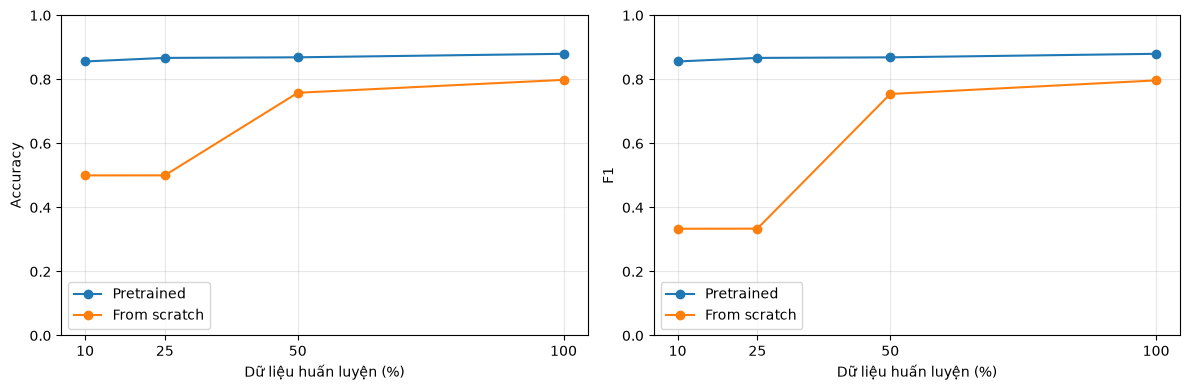

In [11]:
# Mỗi nhãn có một thứ tự ngẫu nhiên cố định; lấy tiền tố để bảo đảm lồng nhau.
rng = np.random.default_rng(SEED)
training_labels = np.asarray(train_data["label"])
class_orders = {label: rng.permutation(np.flatnonzero(training_labels == label)) for label in (0, 1)}
subsets = {}
previous_indices = set()
for fraction in DATA_FRACTIONS:
    indices = np.concatenate([
        order[:max(1, int(round(len(order) * fraction)))] for order in class_orders.values()
    ])
    indices = np.sort(indices)
    assert previous_indices.issubset(set(indices.tolist()))
    previous_indices = set(indices.tolist())
    subsets[fraction] = train_data.select(indices.tolist())

experiment3_results = {}
experiment3_rows = []
for fraction in DATA_FRACTIONS:
    for mode, name in [("scratch", "From scratch"), ("pretrained", "Pretrained")]:
        print(f"Dữ liệu {fraction:.0%} | {name}")
        # Luôn khởi tạo lại, kể cả mức 100%.
        result = run_experiment(mode, subsets[fraction])
        experiment3_results[(fraction, mode)] = result
        experiment3_rows.append({"Training data": f"{fraction:.0%}",
                                 "# Examples": len(subsets[fraction]), "Model": name,
                                 "Accuracy": result["Accuracy"], "F1": result["F1"]})
experiment3_table = pd.DataFrame(experiment3_rows)
display(experiment3_table)
for fraction in DATA_FRACTIONS:
    print_difference(experiment3_results[(fraction, "pretrained")],
                     experiment3_results[(fraction, "scratch")],
                     f"Prediction 3 — {fraction:.0%}: Pretrained trừ From scratch")
for mode in ("scratch", "pretrained"):
    full = experiment3_results[(1.0, mode)]
    small = experiment3_results[(0.1, mode)]
    print(f"{mode}: giảm 100% → 10%: Accuracy={100*(full['Accuracy']-small['Accuracy']):+.3f} "
          f"điểm %; F1={100*(full['F1']-small['F1']):+.3f} điểm %")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, metric in zip(axes, ["Accuracy", "F1"]):
    for mode, name in [("pretrained", "Pretrained"), ("scratch", "From scratch")]:
        axis.plot([100*f for f in DATA_FRACTIONS],
                  [experiment3_results[(f, mode)][metric] for f in DATA_FRACTIONS],
                  marker="o", label=name)
    axis.set(xlabel="Dữ liệu huấn luyện (%)", ylabel=metric,
             xticks=[10, 25, 50, 100], ylim=(0, 1))
    axis.grid(alpha=0.3)
    axis.legend()
fig.tight_layout()
fig.savefig(LAB_DIR / "data_efficiency.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

## 17. Experiment 4 — Maximum Sequence Length

In [12]:
# Padding cố định đến T=max_length; self-attention có chi phí O(T²).
# T lớn giữ thêm nội dung khi truncation, nhưng lợi ích phải đọc từ số đo.
experiment4_results = {}
for length in SEQUENCE_LENGTHS:
    print("Max length:", length)
    experiment4_results[length] = run_experiment("pretrained", train_data, max_length=length)
memory_method = ("CUDA max_memory_allocated" if DEVICE.type == "cuda"
                 else "RSS tiến trình, lấy mẫu 10 ms")
experiment4_table = pd.DataFrame([
    {"Max length": length, "Accuracy": result["Accuracy"], "F1": result["F1"],
     "Training time": result["Training time"],
     "GPU/CPU peak memory": result["peak_mib"]}
    for length, result in experiment4_results.items()
])
display(experiment4_table)
print(f"Thời gian: giây; bộ nhớ: MiB; phương pháp: {memory_method}.")
print("Phạm vi đo: training + validation + lưu checkpoint; không tính khởi tạo và test.")
if DEVICE.type == "cpu":
    print("RSS gồm bộ nhớ kernel hiện có; peak được lấy lại trong từng lần chạy.")
    display(pd.DataFrame([
        {"Max length": length, "RSS tăng so với đầu lần chạy (MiB)": result["extra_mib"]}
        for length, result in experiment4_results.items()
    ]))
for smaller, larger in combinations(SEQUENCE_LENGTHS, 2):
    print_difference(experiment4_results[larger], experiment4_results[smaller],
                     f"Max length {larger} trừ {smaller}:", memory=True)


Max length: 64


Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (8 outputs left out)

[transformers] BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch 1/3: loss=0.2658, validation Accuracy=0.9070, F1=0.9070
Epoch 2/3: loss=0.1401, validation Accuracy=0.9138, F1=0.9138
Epoch 3/3: loss=0.0695, validation Accuracy=0.9160, F1=0.9160


,Max length,Accuracy,F1,Training time,GPU/CPU peak memory
0,64,0.83292,0.832794,314.738910,2172.637695
1,128,0.87968,0.879678,512.594636,2578.470215
2,256,0.91476,0.914737,986.185847,3895.986816


Thời gian: giây; bộ nhớ: MiB; phương pháp: CUDA max_memory_allocated.
Phạm vi đo: training + validation + lưu checkpoint; không tính khởi tạo và test.
Max length 128 trừ 64:
Δ Accuracy: +4.676 điểm %; Δ macro-F1: +4.688 điểm %; Δ thời gian: +197.86 s
Δ peak memory: +405.83 MiB
Max length 256 trừ 64:
Δ Accuracy: +8.184 điểm %; Δ macro-F1: +8.194 điểm %; Δ thời gian: +671.45 s
Δ peak memory: +1723.35 MiB
Max length 256 trừ 128:
Δ Accuracy: +3.508 điểm %; Δ macro-F1: +3.506 điểm %; Δ thời gian: +473.59 s
Δ peak memory: +1317.52 MiB


## 18. Experiment 5 — Domain Shift

In [13]:
# Amazon Polarity: test chính thức, 0=negative, 1=positive; không có nhãn trung tính.
# Ghép tiêu đề và nội dung đánh giá sản phẩm; không dùng B để chọn checkpoint.
amazon_test = load_dataset(DOMAIN_B_DATASET, split="test")
amazon_test = normalize_binary_labels(amazon_test)
assert set(amazon_test.unique("label")) == {0, 1}

def product_to_text(batch):
    return {"text": [(title + "\n" + content).strip()
                     for title, content in zip(batch["title"], batch["content"])],
            "label": batch["label"]}

product_test = amazon_test.map(product_to_text, batched=True,
                               remove_columns=amazon_test.column_names)
# Tái sử dụng chỉ khi toàn bộ chữ ký cấu hình và split khớp.
domain_run = run_experiment("pretrained", train_data, reuse=experiment1_pretrained)
assert domain_run["signature"] == training_signature("pretrained", train_data, MAX_LENGTH)
release_memory()
application_model = create_model("pretrained")
application_model.load_state_dict(torch.load(
    domain_run["checkpoint_path"], map_location=DEVICE, weights_only=True
))
in_domain_scores, imdb_predictions = collect_predictions(application_model, test_data, MAX_LENGTH)
out_domain_scores, product_predictions = collect_predictions(application_model, product_test, MAX_LENGTH)
domain_table = pd.DataFrame([
    {"Domain": domain, "Dataset": dataset, "# Examples": len(rows),
     "Accuracy": scores["Accuracy"], "F1": scores["F1"]}
    for domain, dataset, rows, scores in [
        ("A — phim", "stanfordnlp/imdb (test)", imdb_predictions, in_domain_scores),
        ("B — sản phẩm", DOMAIN_B_DATASET + " (test)", product_predictions, out_domain_scores)]
])
display(domain_table)
print(f"In-domain trừ out-of-domain: Accuracy="
      f"{100*(in_domain_scores['Accuracy']-out_domain_scores['Accuracy']):+.3f} điểm %; "
      f"F1={100*(in_domain_scores['F1']-out_domain_scores['F1']):+.3f} điểm %")
product_errors = product_predictions.loc[~product_predictions["correct"]].copy()
print("Một số dự đoán sai thực tế ở Domain B:")
if product_errors.empty:
    print("Không có mẫu sai trong tập đánh giá này.")
else:
    for row in product_errors.head(5).itertuples():
        print(f"\nID={row.sample_id}; thật={LABELS[row.true_label]}; "
              f"dự đoán={LABELS[row.predicted_label]}; confidence={row.confidence:.4f}")
        print(row.text)

README.md:   0%|          | 0.00/6.81k [00:00<?, ?B/s]

c:\Users\tasdus_117\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\tasdus_117\.cache\huggingface\hub\datasets--fancyzhx--amazon_polarity. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\tasdus_117\AppData\Local\Programs\Python\Python312\Lib\site-packages

amazon_polarity/train-00000-of-00004.par(…): reconstructing file:   0%|          |  0.00B /  260MB            

amazon_polarity/train-00000-of-00004.par(…): downloading bytes:           |  0.00B            

amazon_polarity/train-00001-of-00004.par(…): reconstructing file:   0%|          |  0.00B /  258MB            

amazon_polarity/train-00001-of-00004.par(…): downloading bytes:           |  0.00B            

... (12 outputs left out)

[transformers] BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Map:   0%|          | 0/400000 [00:00<?, ? examples/s]

,Domain,Dataset,# Examples,Accuracy,F1
0,A — phim,stanfordnlp/imdb (test),25000,0.879680,0.879678
1,B — sản phẩm,fancyzhx/amazon_polarity (test),400000,0.900883,0.900730


In-domain trừ out-of-domain: Accuracy=-2.120 điểm %; F1=-2.105 điểm %
Một số dự đoán sai thực tế ở Domain B:

ID=2; thật=negative; dự đoán=positive; confidence=0.7175
Batteries died within a year ...
I bought this charger in Jul 2003 and it worked OK for a while. The design is nice and convenient. However, after about a year, the batteries would not hold a charge. Might as well just get alkaline disposables, or look elsewhere for a charger that comes with batteries that have better staying power.

ID=9; thật=negative; dự đoán=positive; confidence=0.5404
Not an "ultimate guide"
Firstly,I enjoyed the format and tone of the book (how the author addressed the reader). However, I did not feel that she imparted any insider secrets that the book promised to reveal. If you are just starting to research law school, and do not know all the requirements of admission, then this book may be a tremendous help. If you have done your homework and are looking for an edge when it comes to admissions, I 

## 19. Application — Sentiment Classification

,Accuracy,Macro-Precision,Macro-Recall,Macro-F1
0,0.87968,0.879702,0.87968,0.879678


,precision,recall,f1-score,support
negative,0.876786,0.88352,0.880140,12500.0
positive,0.882619,0.87584,0.879216,12500.0


,sample_id,text,true_label,predicted_label,p_negative,p_positive,confidence,correct
0,0,I love sci-fi and am willing to put up with a ...,0,0,0.979951,0.020049,0.979951,True
1,1,"Worth the entertainment value of a rental, esp...",0,1,0.075473,0.924527,0.924527,False
2,2,its a totally average film with a few semi-alr...,0,0,0.985292,0.014708,0.985292,True
3,3,STAR RATING: ***** Saturday Night **** Friday ...,0,0,0.829769,0.170231,0.829769,True
4,4,"First off let me say, If you haven't enjoyed a...",0,1,0.012192,0.987808,0.987808,False


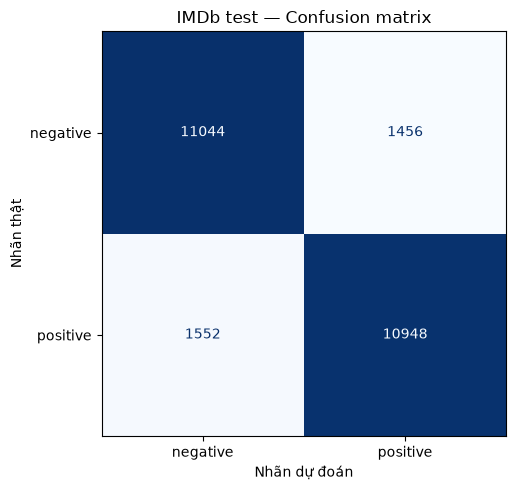

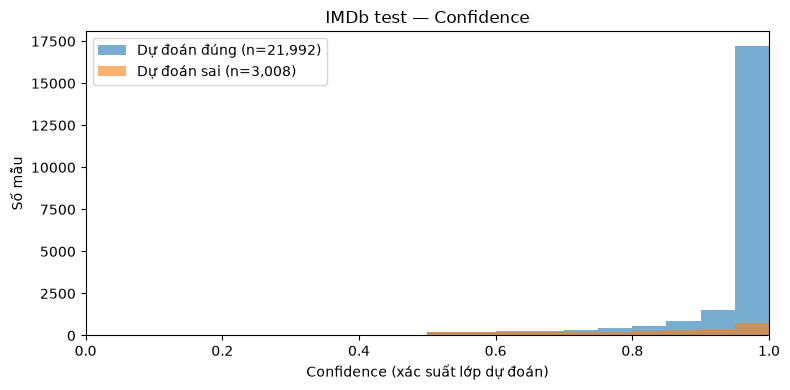

In [14]:
# imdb_predictions giữ ID, toàn văn, nhãn thật/dự đoán và softmax hai lớp để phân tích lỗi.
assert len(imdb_predictions) == len(test_data)
assert domain_run["signature"] == training_signature("pretrained", train_data, MAX_LENGTH)
y_true = imdb_predictions["true_label"].to_numpy()
y_pred = imdb_predictions["predicted_label"].to_numpy()
application_scores = metric_scores(y_true, y_pred)
display(pd.DataFrame([application_scores]).rename(columns={
    "Precision": "Macro-Precision", "Recall": "Macro-Recall", "F1": "Macro-F1"
}))
report = classification_report(y_true, y_pred, labels=[0, 1], target_names=LABELS,
                               output_dict=True, zero_division=0)
display(pd.DataFrame(report).T.loc[list(LABELS), ["precision", "recall", "f1-score", "support"]])
display(imdb_predictions.head())

matrix = confusion_matrix(y_true, y_pred, labels=[0, 1])
fig, axis = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(matrix, display_labels=LABELS).plot(
    ax=axis, cmap="Blues", values_format="d", colorbar=False
)
axis.set(xlabel="Nhãn dự đoán", ylabel="Nhãn thật", title="IMDb test — Confusion matrix")
fig.tight_layout()
fig.savefig(LAB_DIR / "confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# Cùng tập dự đoán và cùng bins; confidence là softmax của lớp được dự đoán.
bins = np.linspace(0, 1, 21)
fig, axis = plt.subplots(figsize=(8, 4))
for correct, name in [(True, "Dự đoán đúng"), (False, "Dự đoán sai")]:
    values = imdb_predictions.loc[imdb_predictions["correct"] == correct, "confidence"]
    axis.hist(values, bins=bins, alpha=0.6, label=f"{name} (n={len(values):,})")
axis.set(xlabel="Confidence (xác suất lớp dự đoán)", ylabel="Số mẫu",
         title="IMDb test — Confidence", xlim=(0, 1))
axis.legend()
fig.tight_layout()
fig.savefig(LAB_DIR / "confidence_analysis.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)